# Football Managerial Decision Analytics — Chapter 01
## Data source, provenance, quality audit and exploratory analysis

> **Data.** StatsBomb Open Data (https://github.com/hudl/open-data), provided by StatsBomb / Hudl, used for educational, non-commercial research. Raw data are downloaded from the official repository at run time and are not redistributed here. Every figure carries its chart ID from `docs/VISUALIZATION_CATALOGUE.md`.

This notebook is one chapter of the research record. All logic lives in the shared `src/` package; the cells call it. The same charts are available interactively in the Streamlit dashboard (`streamlit run app.py`).

In [1]:
# Setup — locate (or fetch) the project code, import the shared package, load the workspace
import os, subprocess, sys, time
from pathlib import Path

REPO_URL = "https://github.com/blazingarrows1525/football-managerial-decision-analytics"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "workspace.py").exists()), None)
if ROOT is None:  # opened on its own (e.g. Google Colab): fetch the project code once, next to this notebook
    ROOT = Path.cwd() / "football-managerial-decision-analytics"
    if not (ROOT / "src" / "workspace.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("FMA_PROJECT_ROOT", str(ROOT))  # data cache and outputs live inside the project folder

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.reporting.notebook_tools import (catalogue, explorer, implication, interpret, limitation, show, start,
                                          timed, timings)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:.3f}".format)
RUN_ADVANCED_GALLERY = True   # heavier, optional sections; the core story does not depend on them
SEED = 42                             # every resampling and model step takes this seed explicitly

ws = start(seed=SEED)                 # first run downloads and parses; later runs read the processed cache
B, T, FOCUS = ws.bundle, ws.tables, ws.focus
tm = ws.team_matches()                # the focus team's matches in date order
print(f"Advanced sections: {'on' if RUN_ADVANCED_GALLERY else 'off'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

**Workspace ready in 2.9s** (processed cache) · 1. Bundesliga 2023/2024 · 34 matches · 137,765 events · focus team **Bayer Leverkusen** · figures: static PNG (FMA_STATIC=1) · seed 42

Advanced sections: on · Python 3.10.11 · pandas 2.1.4


## B · Data source, provenance and quality

**Research question.** Where do the data come from, under which terms, and can the parsed tables be trusted
for the analyses built on them?

**Data and method.** The download client records the URL, byte size, SHA-256 hash and write time of every raw
file. Parsed tables are checked against sixteen domain rules and fourteen table contracts (grain, key, required
fields).

In [2]:
from src.data import provenance
from src.data.schemas import check_contracts

man = B.manifest
display(provenance.source_register()[["source", "role_in_project", "terms", "status"]])
display(man.groupby(["resource", "status"]).agg(files=("relative_path", "size"), MB=("bytes", lambda s: round(s.sum() / 1e6, 2))))
display(man[["relative_path", "bytes", "sha256", "file_written_utc"]].head(4))
print("Terms recorded from the source licence:")
for t in provenance.TERMS_SUMMARY:
    print(" -", t)
interpret(f"{len(man)} raw files ({man.bytes.sum() / 1e6:.1f} MB) were read with {int((man.status != 'ok').sum())} failures; "
          f"each has a SHA-256 hash in `data/manifest/source_manifest.json`. The user agreement allows research "
          f"use and public sharing of analysis but not redistribution of the data, so this repository contains "
          f"no raw or processed event tables.")

,source,role_in_project,terms,status
0,StatsBomb Open Data (Hudl),"PRIMARY: competitions, matches (incl. managers...",StatsBomb Public Data User Agreement (LICENSE....,used
1,API-Football v3,"OPTIONAL enrichment (coach, injuries, fixtures...",Subscription terms of the provider; coverage v...,not used by default (no key supplied)
2,Metrica Sports sample data,OPTIONAL separate tracking demo only (anonymis...,See repository licence,not used
3,football-data.co.uk,OPTIONAL supplementary team-level results only,See website notes,not used
4,User-supplied files,USER_DATA mode (StatsBomb-format JSON) and opt...,User must hold rights to use the files,optional


,,files,MB
resource,status,,
competitions,ok,1,0.030
events,ok,34,119.220
lineups,ok,34,0.730
matches,ok,1,0.060


,relative_path,bytes,sha256,file_written_utc
0,competitions.json,34887,e6cd42f5d8956d6aa30fb917ce8d4c3b3df1879a93f02f...,2026-11-01T16:47:55+00:00
1,matches/9/281.json,63079,13dff90f126d9f73da410ae3292b2773744657d3ba968a...,2026-11-01T16:47:55+00:00
2,events/3895052.json,3205861,ecc00b4e7ddd0154532329091d5d82fd7de4b9f6aa8da1...,2026-11-01T16:47:56+00:00
3,lineups/3895052.json,22124,485e5e4f06136578a5dd18648397808110978cadb36a63...,2026-11-01T16:47:56+00:00


Terms recorded from the source licence:
 - The data are provided for analysis and research; analysis and conclusions may be shared publicly (1.1).
 - The user may not edit, distort, distribute, reproduce, sell or provide the data to third parties (1.2.1).
 - No commercial exploitation of the data or of analysis derived from it (1.2.2).
 - Publications of analysis must be accredited with the StatsBomb brand logo (1.4).
 - The service is provided as is; StatsBomb may withdraw it at any time (2.1, 3.2).


**Interpretation.** 70 raw files (120.1 MB) were read with 0 failures; each has a SHA-256 hash in `data/manifest/source_manifest.json`. The user agreement allows research use and public sharing of analysis but not redistribution of the data, so this repository contains no raw or processed event tables.

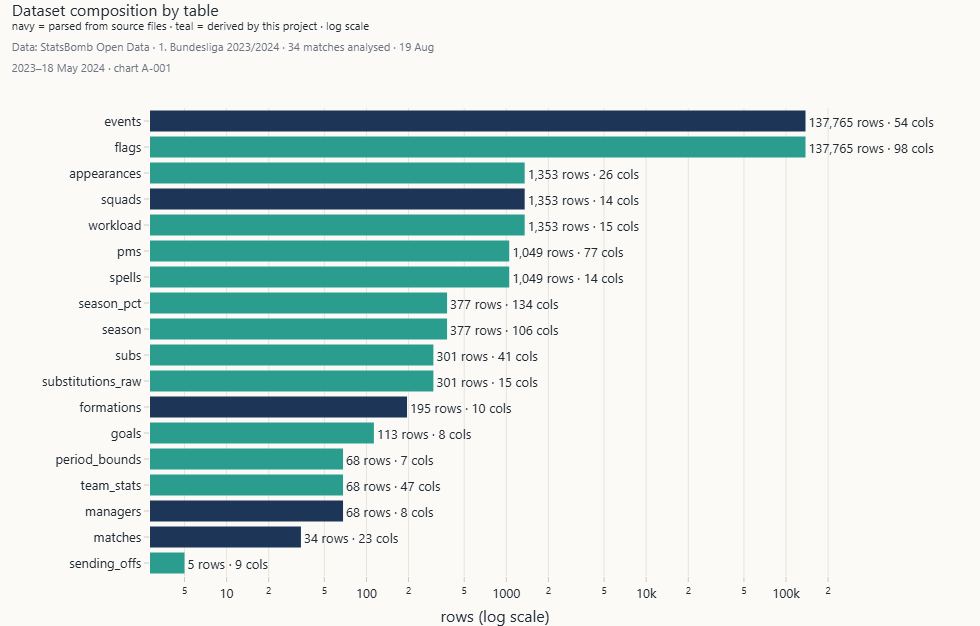

`A-001` Dataset composition by table · *Method:* Row and column counts of every canonical and derived table; log scale.

,table,origin,rows,grain,status,duplicate_keys
0,matches,source,34,one row per match,PASS,0
1,managers,source,68,one row per match and team,PASS,0
2,events,source,137765,one row per event,PASS,0
3,squads,source,1353,"one row per match, team and squad player",PASS,0
4,appearances,derived,1353,one row per match and squad player,PASS,0
5,spells,derived,1049,one row per continuous on-pitch spell,PASS,0
6,goals,derived,113,one row per goal,PASS,0
7,formations,source,195,one row per formation record,PASS,0
8,flags,derived,137765,one row per event,PASS,0
9,pms,derived,1049,one row per player and match,PASS,0


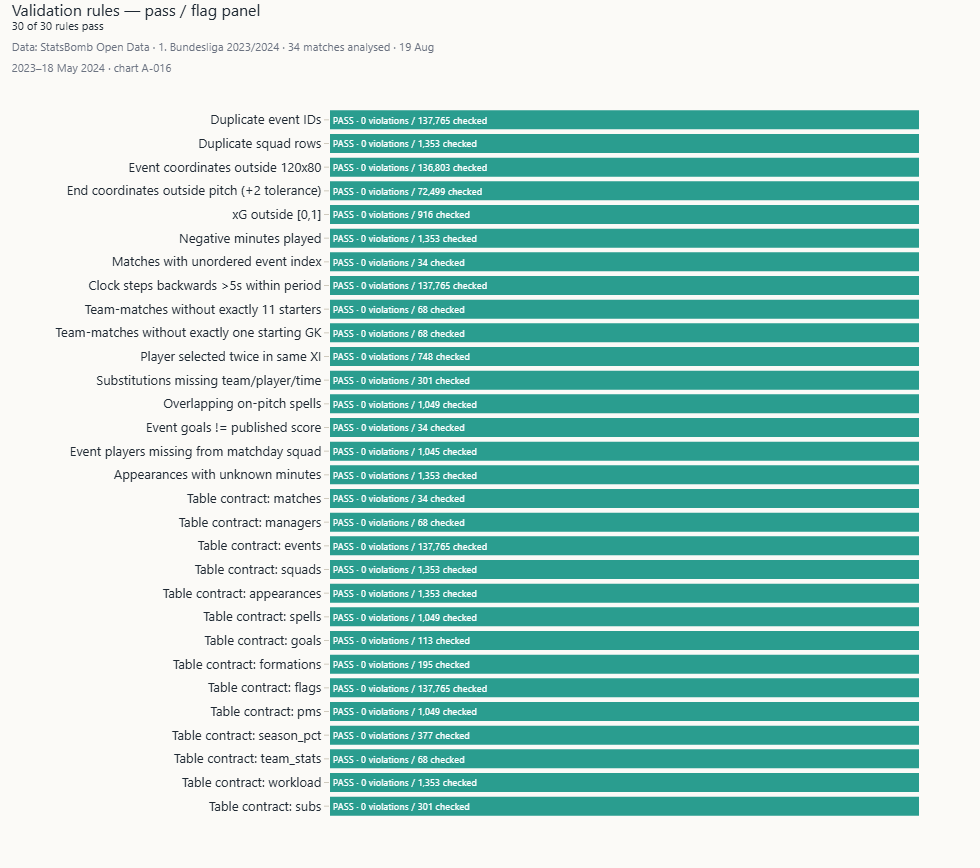

`A-016` Validation rule pass / fail panel · *Method:* Sixteen domain rules plus fourteen table contracts.

**Interpretation.** 16 of 16 domain rules and 14 of 14 table contracts pass: event IDs are unique, coordinates lie on the 120 × 80 pitch, xG is within [0, 1] and attached only to shots, every team-match has eleven starters and one goalkeeper, on-pitch spells do not overlap and the goals rebuilt from events equal the published scores.

**Limitation.** Passing validation shows internal consistency, not that the provider's event tagging is error-free.

In [3]:
show("A-001", ws)
contracts = check_contracts(B)
display(contracts[["table", "origin", "rows", "grain", "status", "duplicate_keys"]])
show("A-016", ws)
q = B.quality
interpret(f"{int((q.status == 'PASS').sum())} of {len(q)} domain rules and {int((contracts.status == 'PASS').sum())} of "
          f"{len(contracts)} table contracts pass: event IDs are unique, coordinates lie on the 120 × 80 pitch, xG is "
          f"within [0, 1] and attached only to shots, every team-match has eleven starters and one goalkeeper, "
          f"on-pitch spells do not overlap and the goals rebuilt from events equal the published scores.")
limitation("Passing validation shows internal consistency, not that the provider's event tagging is error-free.")

### Missing values, duplicates and outliers

**Question.** Which gaps are structural, and are extreme values errors or football?

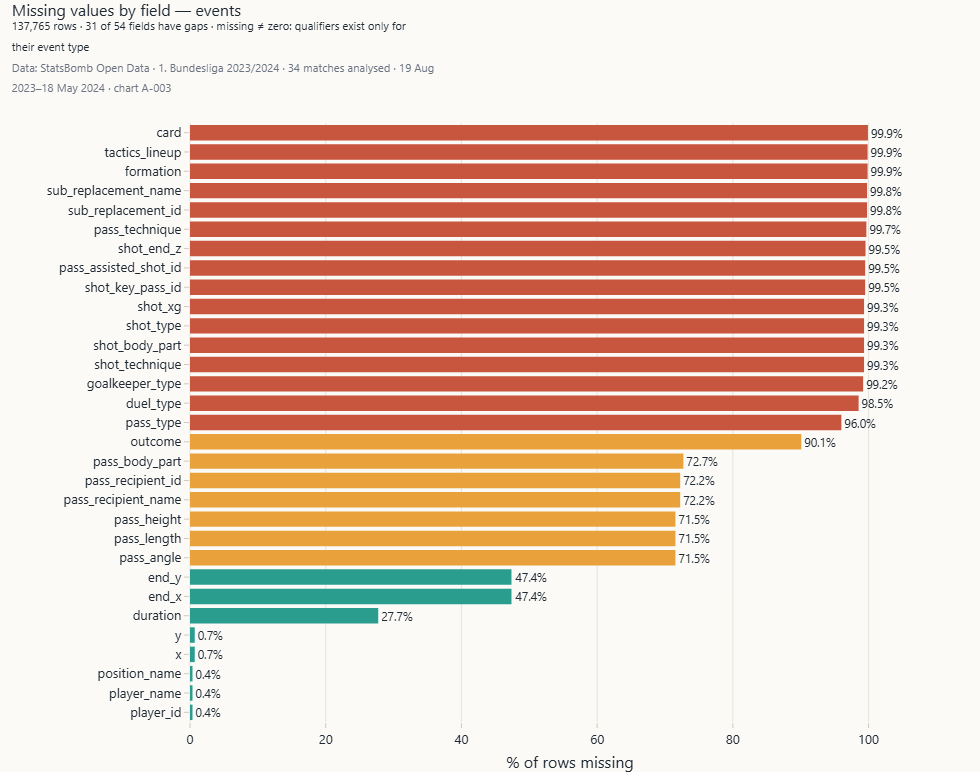

`A-003` Missingness by field · *Method:* Share of missing values per event field. · *Caveat:* Most gaps are structural: a qualifier exists only for its event type.

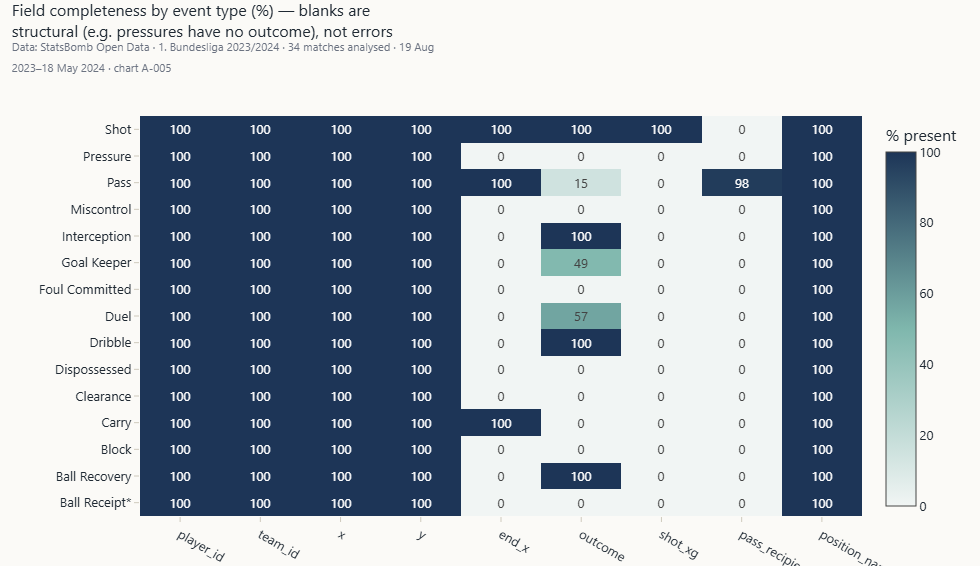

`A-005` Missingness by event type · *Method:* Completeness of each field within each event type.

**Interpretation.** Most fields are sparse by design: `shot_xg` is present on 0.7% of all events but on 100% of the 916 shots; pass end locations exist for 100% of passes. Missing values are kept as missing and are never read as zero.

In [4]:
show("A-003", ws)
show("A-005", ws)
ev = T["events"]
shots = ev[ev.type == "Shot"]
interpret(f"Most fields are sparse by design: `shot_xg` is present on {ev.shot_xg.notna().mean():.1%} of all events but on "
          f"{shots.shot_xg.notna().mean():.0%} of the {len(shots):,} shots; pass end locations exist for "
          f"{ev.loc[ev.type == 'Pass', 'end_x'].notna().mean():.0%} of passes. Missing values are kept as missing and "
          f"are never read as zero.")

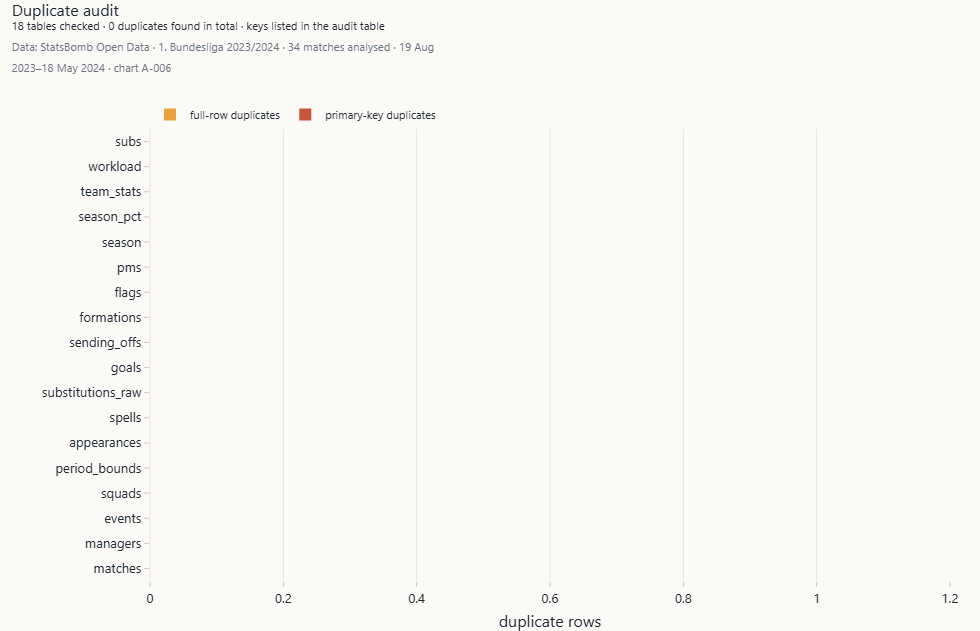

`A-006` Duplicate full-row and primary-key counts · *Method:* Counts of duplicated full rows and duplicated primary keys per table.

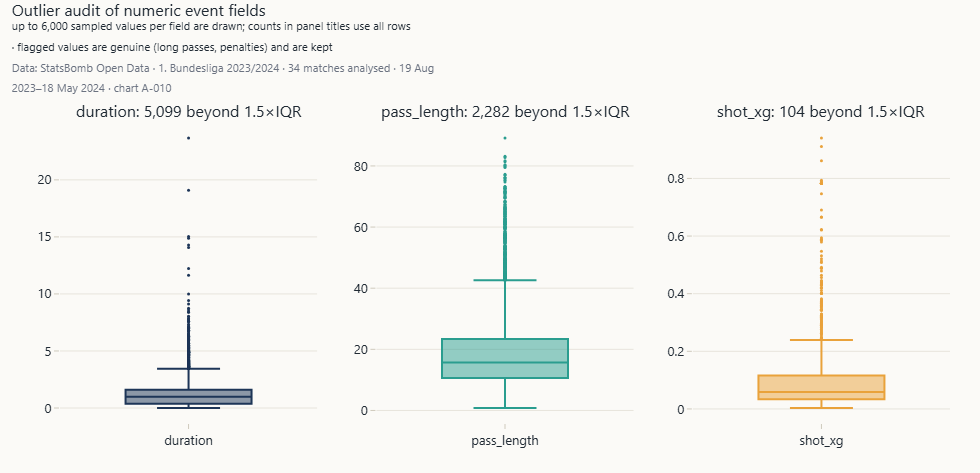

`A-010` Outlier distributions · *Method:* Box plots with the count beyond 1.5 × IQR. · *Caveat:* Flagged values are genuine events and are kept.

**Interpretation.** 0 duplicated rows and 0 duplicated keys across 18 tables. Values beyond 1.5 × IQR are real events (long passes, penalties, long stoppages) and are kept.

In [5]:
from src.visualization import audit
dups = audit.duplicate_audit_table(B)
show("A-006", ws)
show("A-010", ws)
interpret(f"{int(dups.full_row_duplicates.sum())} duplicated rows and {int(dups.key_duplicates.fillna(0).sum())} duplicated keys across "
          f"{len(dups)} tables. Values beyond 1.5 × IQR are real events (long passes, penalties, long stoppages) and are kept.")

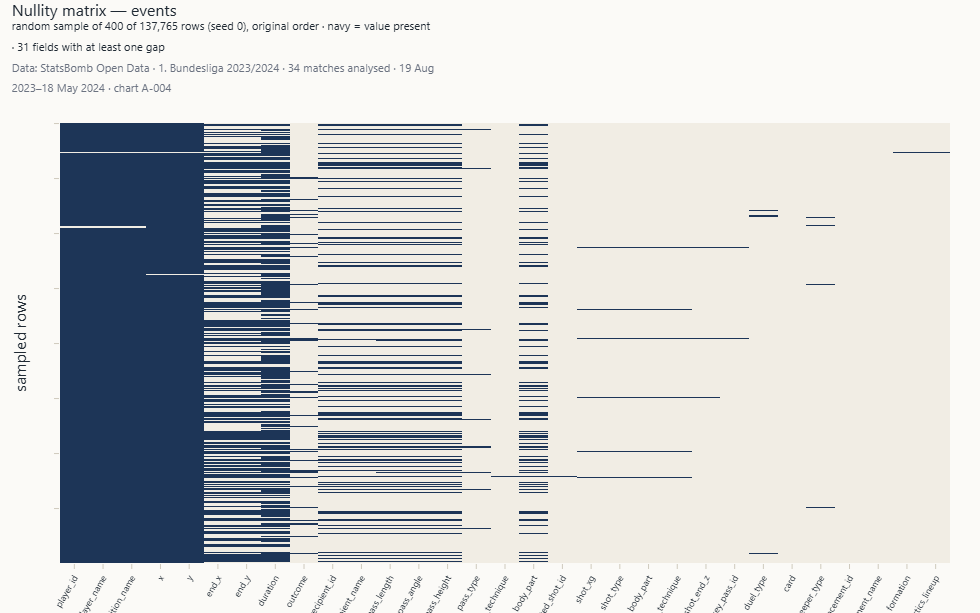

`A-004` Missingness matrix · *Method:* Nullity of a seeded random sample of 400 event rows.

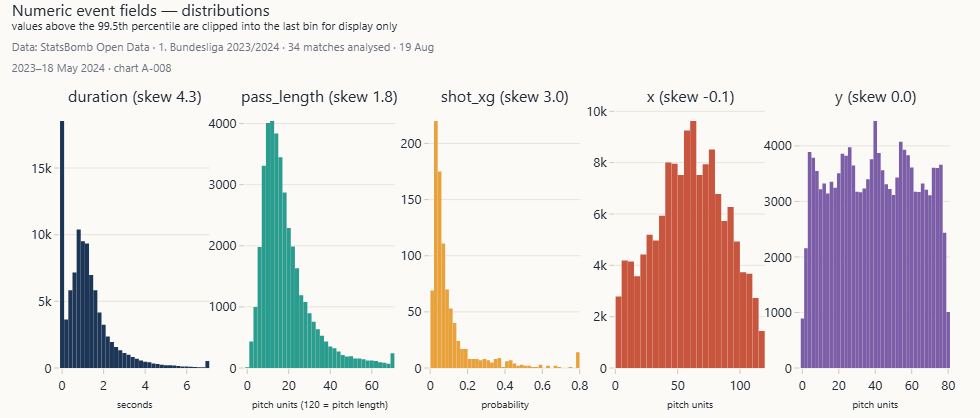

`A-008` Numeric field distributions · *Method:* Histograms with skewness; display clipped at the 99.5th percentile.

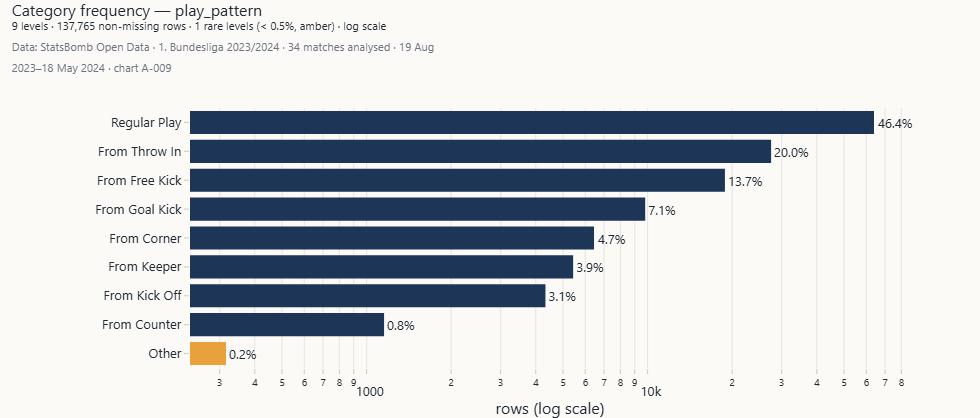

`A-009` Categorical frequency and rare categories · *Method:* Level frequencies on a log axis; levels under 0.5% flagged.

In [6]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    show("A-004", ws)
    show("A-008", ws)
    show("A-009", ws)

### What the data support, and what they do not

**Question.** Which analytical inputs exist? The answer is read from the tables, not assumed.

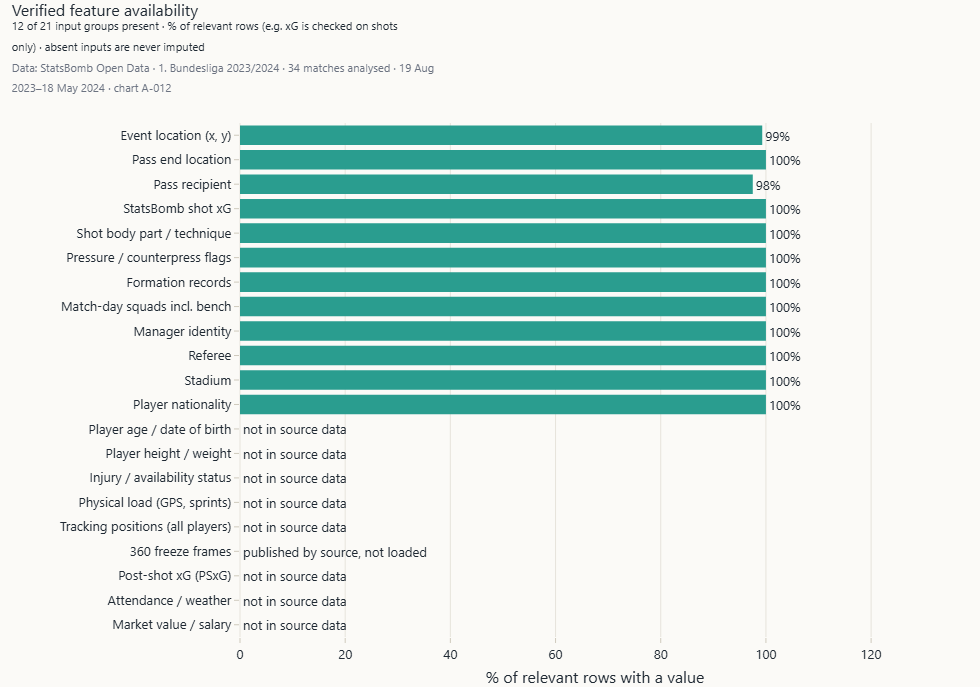

`A-012` Feature availability · *Method:* Verified from the loaded tables; absent modalities are listed, never imputed.

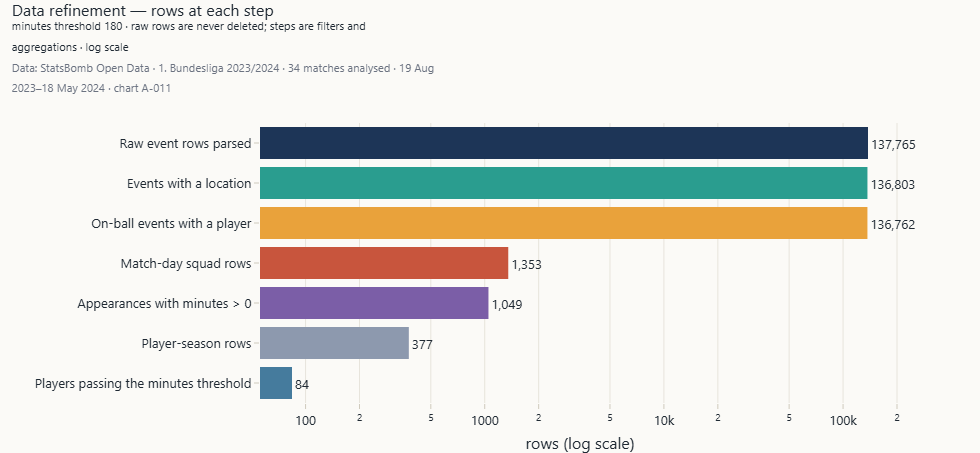

`A-011` Before / after refinement funnel · *Method:* Row counts from raw events to eligible player-seasons.

**Interpretation.** 12 of 21 input groups are present. Not available: Player age / date of birth; Player height / weight; Injury / availability status; Physical load (GPS, sprints); Tracking positions (all players); 360 freeze frames; Post-shot xG (PSxG); Attendance / weather; Market value / salary. None of these is imputed, and no chart that needs them is drawn.

**Managerial implication.** Selection and substitution tools built on this data cannot know who is injured or tired; the analyst must supply availability.

In [7]:
show("A-012", ws)
show("A-011", ws)
fa = audit.feature_availability_table(B)
absent = fa[fa.status != "available"].feature.tolist()
interpret(f"{int((fa.status == 'available').sum())} of {len(fa)} input groups are present. Not available: "
          + "; ".join(absent) + ". None of these is imputed, and no chart that needs them is drawn.")
implication("Selection and substitution tools built on this data cannot know who is injured or tired; the analyst "
            "must supply availability.")

,match_id,frames,joined_to_events
0,3895052,3181,3181
1,3895158,3318,0


**Interpretation.** 2 optional 360 file(s) are cached. 1 of them share no identifier with their event file — a source inconsistency; those frames are not used.

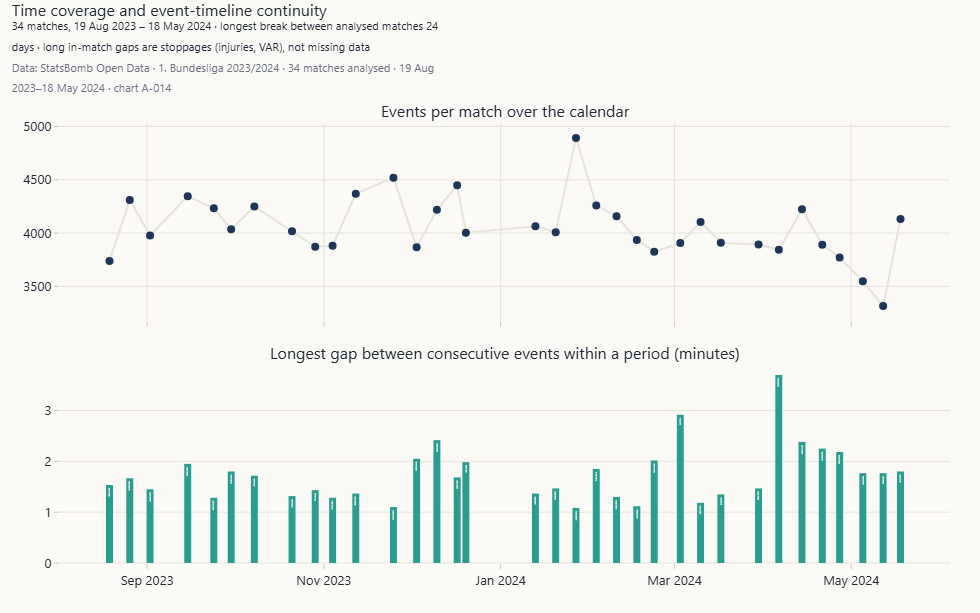

`A-014` Time coverage and event-timeline gaps · *Method:* Events per match over the calendar and the longest within-period gap.

In [8]:
# Optional 360 freeze frames: published by the source, downloaded per match only on request.
# When files are cached, check that their identifiers actually join to the event file before using them.
import json
d360 = B.config.raw_dir / "three-sixty"
rows = []
for p in sorted(d360.glob("*.json")) if d360.exists() else []:
    frames = json.loads(p.read_text(encoding="utf-8"))
    ids = set(ev.loc[ev.match_id == int(p.stem), "event_id"])
    rows.append({"match_id": int(p.stem), "frames": len(frames), "joined_to_events": len(ids & {f["event_uuid"] for f in frames})})
check360 = pd.DataFrame(rows)
if len(check360):
    display(check360)
    bad = check360[check360.joined_to_events == 0]
    interpret(f"{len(check360)} optional 360 file(s) are cached. " + (f"{len(bad)} of them share no identifier with their "
              f"event file — a source inconsistency; those frames are not used." if len(bad) else "All of them join to their events."))
else:
    print("No 360 file is cached; chart E-129 is reported as implemented_but_unavailable.")
show("A-014", ws)

## C · Feature engineering and exploratory analysis

**Question.** After normalising for playing time and role, how are player metrics distributed and how do they
relate?

**Data and method.** Minutes are rebuilt from the event stream. Per-90 values are `value / minutes × 90` and
percentiles are computed within the player's role group among players above the minutes threshold.

,metric,definition,numerator,denominator,unit,source_fields
0,minutes_played,Actual playing time on pitch incl. stoppage (p...,sum of spell lengths,-,minutes,"events: Starting XI, Substitution, Foul Commit..."
1,goals,Shots with outcome Goal in periods 1-4 (shoot-...,count,-,goals,shot.outcome
2,npxg,Sum of StatsBomb xG on non-penalty shots,sum xG,-,xG,"shot.statsbomb_xg, shot.type"
3,xg,Sum of StatsBomb xG on all shots (periods 1-4),sum xG,-,xG,shot.statsbomb_xg
4,xa,xG of shots assisted by the player's passes (p...,sum xG,-,xG,"pass.assisted_shot_id, shot.statsbomb_xg"
5,shots,Shot events (periods 1-4),count,-,shots,type=Shot
6,shots_on_target,Shots with outcome Goal / Saved / Saved To Post,count,-,shots,shot.outcome
7,assists,Passes flagged goal_assist by StatsBomb,count,-,assists,pass.goal_assist
8,key_passes,Passes flagged shot_assist or goal_assist,count,-,passes,"pass.shot_assist, pass.goal_assist"
9,passes,Pass attempts,count,-,passes,type=Pass


,metric,formula,inputs,caveat
0,per-90 rate,count or value / minutes played × 90,minutes reconstructed from events,null below the minimum-minutes threshold; neve...
1,role percentile,percentile rank of a per-90 value within the p...,eligible players of the same role group,group size is reported; groups under the minim...
2,possession_proxy_pct,team passes / (team passes + opponent passes) ...,pass attempts of both teams,"a pass-share proxy, not timed possession"
3,field_tilt_pct,team final-third touches / both teams' final-t...,touches with x ≥ 80,territory proxy from on-ball events
4,ppda,opponent passes with x ≤ 72 / team tackles + i...,defensive actions in the opponent's build-up zone,lower = more defensive actions per opponent pa...
5,xg_diff,sum of StatsBomb xG for − against in a match,—,xG is the provider's model output
6,expected points (xPts),"mean points over 5,000 simulations in which ev...",per match,assumes independent shots; ignores game state
7,progressive pass,completed pass starting at x ≥ 48 that ends at...,—,project definition; other providers use differ...


84 of 377 player-team rows have at least 180 minutes; 17 have at least 900.


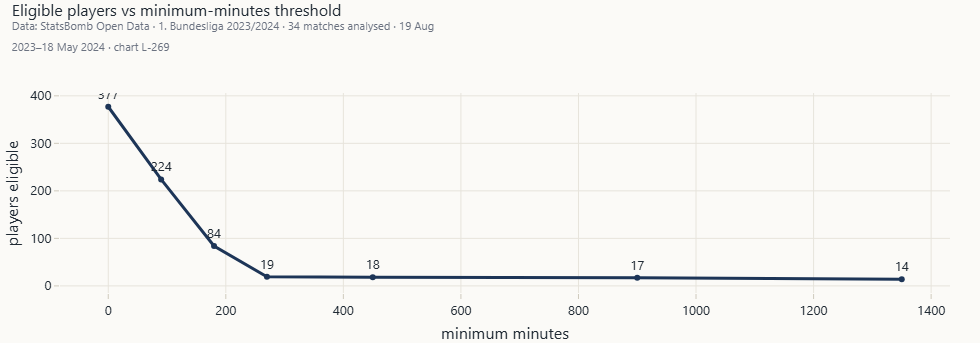

`L-269` Minimum-minutes sensitivity · *Method:* Eligible players by threshold.

In [9]:
from src.features.player_features import metric_dictionary
from src.reporting.report_builder import DERIVED_METRICS
from src.workspace import EDA_METRICS

display(metric_dictionary().head(12))
display(pd.DataFrame(DERIVED_METRICS, columns=["metric", "formula", "inputs", "caveat"]).head(8))
s = B.season
print(f"{int(s.eligible.sum())} of {len(s)} player-team rows have at least {B.config.min_minutes:.0f} minutes; "
      f"{int((s.minutes_played >= 900).sum())} have at least 900.")
show("L-269", ws)

,players,xg_p90,key_passes_p90,progressive_passes_p90,interceptions_p90,pass_completion_pct
role_family,,,,,,
Defender,38,0.020,0.278,1.832,1.396,84.443
Forward,10,0.325,0.724,0.604,0.082,74.807
Goalkeeper,14,0.000,0.000,0.000,0.000,74.776
Midfielder,22,0.034,0.478,1.394,0.976,84.826


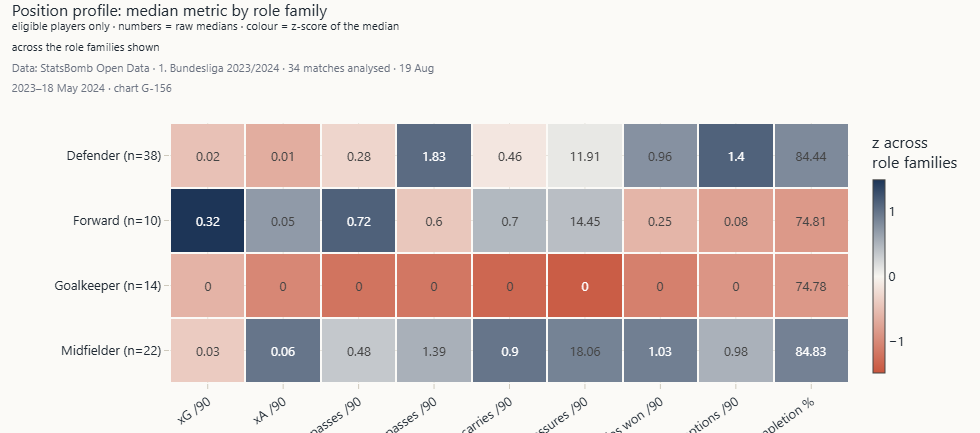

`G-156` Position / role metric profile · *Method:* Median metric by role family (z-coloured, raw values printed).

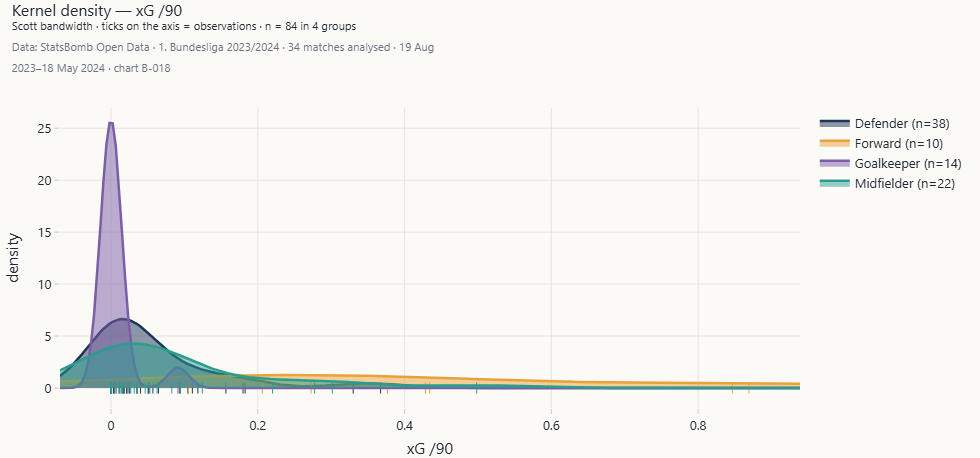

`B-018` KDE by role family · *Method:* Gaussian KDE, Scott bandwidth; rug of points. · *Caveat:* Groups under 5 values are not drawn.

**Interpretation.** Role families separate clearly on some metrics: median xG/90 is highest for Forwards (0.32) and lowest for Defenders (0.02); interceptions/90 peak for Defenders (1.40). Group sizes: Defender 38, Forward 10, Goalkeeper 14, Midfielder 22.

**Managerial implication.** Compare players inside their role group. A raw leaderboard mostly re-discovers positions.

In [10]:
from src.analytics import descriptive as desc
rm = desc.role_medians(B, ["xg_p90", "key_passes_p90", "progressive_passes_p90", "interceptions_p90", "pass_completion_pct"])
display(rm)
show("G-156", ws)
show("B-018", ws, metric="xg_p90")
fams = rm.drop(index="Goalkeeper", errors="ignore")
interpret(f"Role families separate clearly on some metrics: median xG/90 is highest for {fams.xg_p90.idxmax()}s "
          f"({fams.xg_p90.max():.2f}) and lowest for {fams.xg_p90.idxmin()}s ({fams.xg_p90.min():.2f}); interceptions/90 "
          f"peak for {fams.interceptions_p90.idxmax()}s ({fams.interceptions_p90.max():.2f}). Group sizes: "
          + ", ".join(f"{i} {int(n)}" for i, n in rm.players.items()) + ".")
implication("Compare players inside their role group. A raw leaderboard mostly re-discovers positions.")

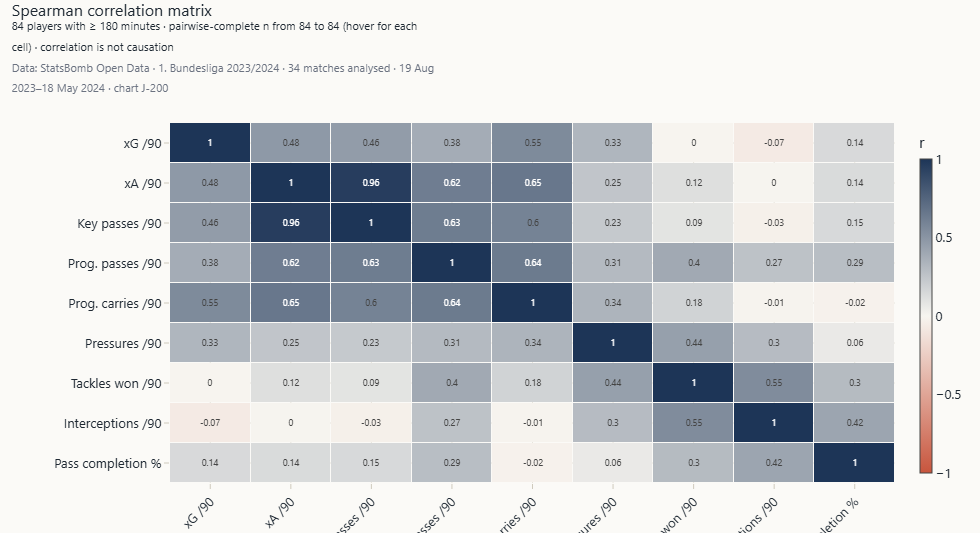

`J-200` Spearman rank correlation matrix · *Method:* Rank-based; robust to skew.

**Interpretation.** Among 84 eligible players the strongest positive rank correlation is between xa_p90 and key_passes_p90 (ρ = 0.96) and the strongest negative between xg_p90 and interceptions_p90 (ρ = -0.07). Pairwise n ranges from 84 to 84.

**Limitation.** Players are nested in teams and opponents are observed only against the focus team; these are descriptive associations.

In [11]:
from src.analytics import statistical_tests as stt
el = ws.eligible()
r, n = stt.correlation_matrix(el, EDA_METRICS, "spearman")
show("J-200", ws)
pairs = r.where(np.triu(np.ones(r.shape, bool), 1)).stack().sort_values()
lo, hi = pairs.index[0], pairs.index[-1]
interpret(f"Among {len(el)} eligible players the strongest positive rank correlation is between {hi[0]} and {hi[1]} "
          f"(ρ = {pairs.iloc[-1]:.2f}) and the strongest negative between {lo[0]} and {lo[1]} (ρ = {pairs.iloc[0]:.2f}). "
          f"Pairwise n ranges from {int(n.values.min())} to {int(n.values.max())}.")
limitation("Players are nested in teams and opponents are observed only against the focus team; these are "
           "descriptive associations.")

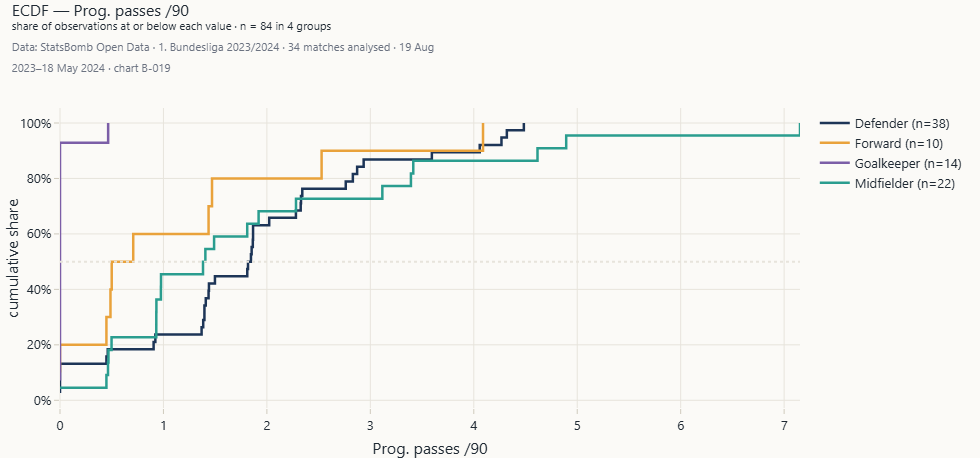

`B-019` ECDF comparison · *Method:* No binning or smoothing.

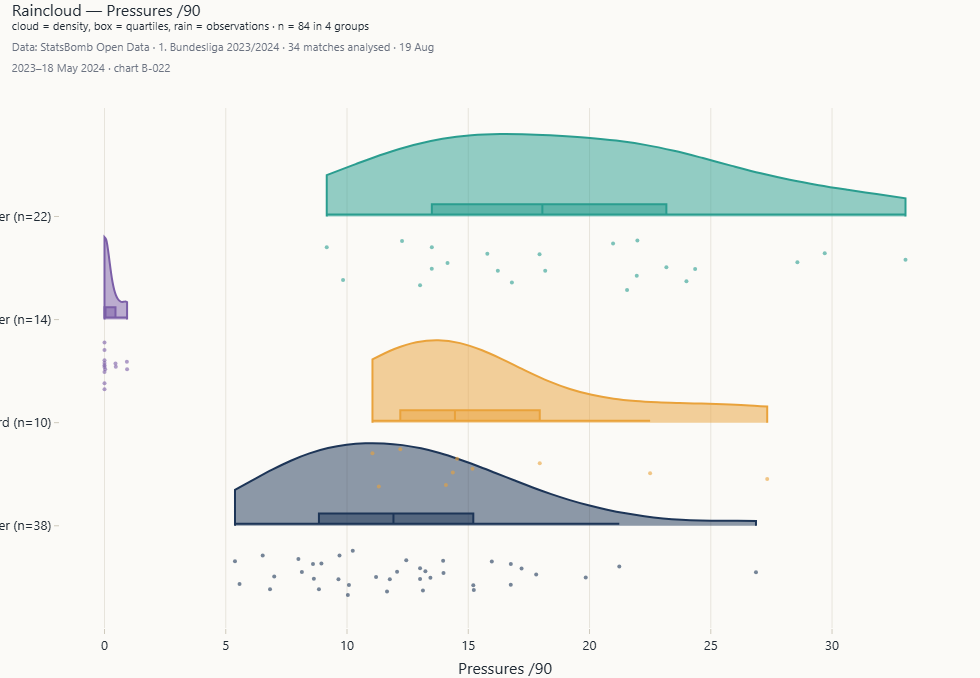

`B-022` Raincloud plot · *Method:* Half-violin, box and points.

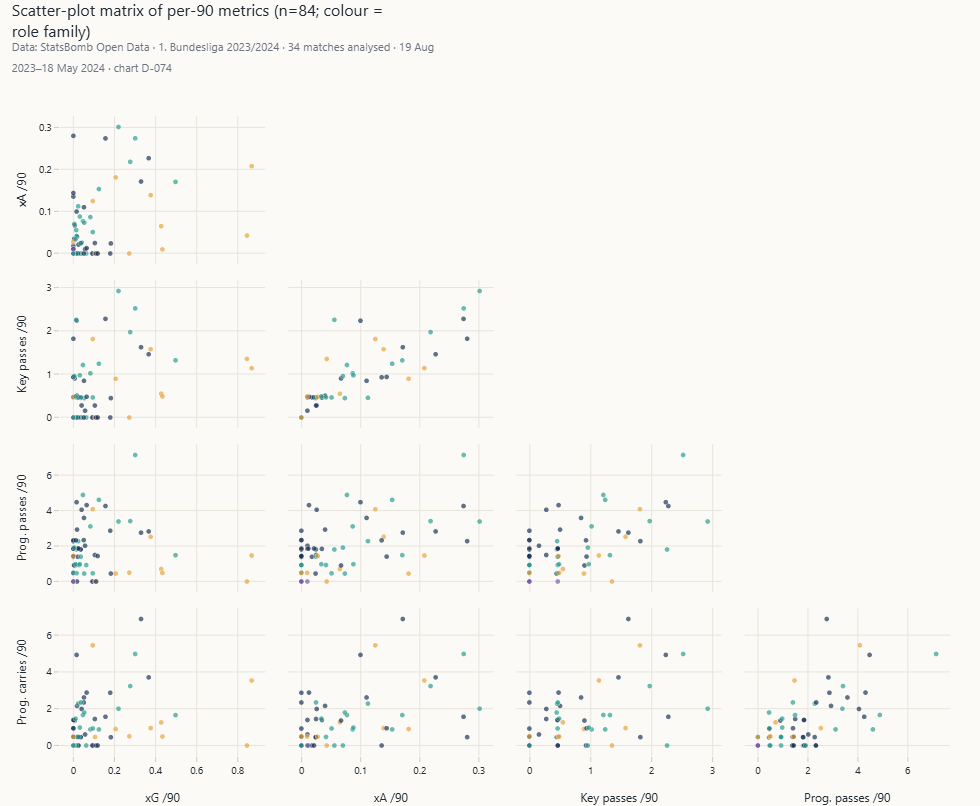

`D-074` Player pair plot · *Method:* Scatter-plot matrix by role family.

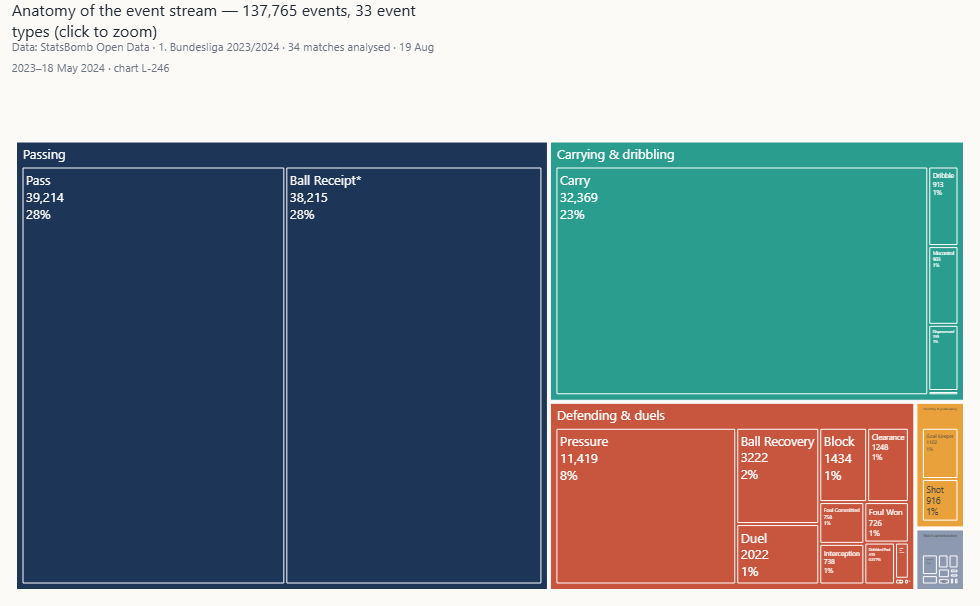

`L-246` Event taxonomy treemap · *Method:* Events by family and type.

In [12]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    show("B-019", ws, metric="progressive_passes_p90")
    show("B-022", ws, metric="pressures_p90")
    show("D-074", ws)
    show("L-246", ws)

In [13]:
display(timings().tail(12))

,step,seconds
9,chart A-009,1.930
10,chart A-012,2.130
11,chart A-011,1.970
12,chart A-014,2.130
13,chart L-269,1.890
14,chart G-156,1.960
15,chart B-018,1.980
16,chart J-200,1.930
17,chart B-019,2.030
18,chart B-022,2.060
